# Tutorial for the YamboScreeningParser class

This tutorial describes the `YamboScreeningParser` class, which reads the screening databases written by Yambo
(`ndb.em1s` for the static screening, `ndb.em1d` for many frequencies and `ndb.pp` for the plasmon pole
approximation, each with its fragments `ndb.<kind>_fragment_<iq>`). For each q point of the IBZ and each frequency
the databases contain the symmetrized matrix

$$X_{\mathbf{G}\mathbf{G}'}(\mathbf{q},\omega) = v^{1/2}_\mathbf{G}(\mathbf{q})\,\chi_{\mathbf{G}\mathbf{G}'}(\mathbf{q},\omega)\,
v^{1/2}_{\mathbf{G}'}(\mathbf{q}) = \epsilon^{-1}_{\mathbf{G}\mathbf{G}'}(\mathbf{q},\omega) - \delta_{\mathbf{G}\mathbf{G}'} ,$$

where $\chi$ is the reducible response function and $v_\mathbf{G}(\mathbf{q}) = 4\pi/|\mathbf{q}+\mathbf{G}|^2$ the
Coulomb interaction (cut, if the run uses a Coulomb cutoff). The class computes the quantities derived from X,
transforms X under a rotation and a translation of the system and writes a new database with a modified X, which Yambo
can then use (e.g. in a GW computation). Since X is symmetrized, none of these operations needs v. The Coulomb
interaction of a run is read from the `ndb.cutoff` and `ndb.RIM` databases by the `YamboCoulombParser` class, and the
quantities in physical units (W, $\chi$) combine the two parsers, e.g. $W = v^{1/2}(1+X)v^{1/2}$:

```python
coul = YamboCoulombParser('SAVE', cutoff='ndb_rim_cutoff')
s = np.sqrt(coul.coulomb(iq, scr.ng))
W = s[:, None] * scr.eps_inv(iq) * s[None, :]
```

We use the static screening (`ndb.em1s`) of a monolayer of hBN computed, with the slab cutoff along z, in the
YamboCoulombParser tutorial (execute that notebook first): 12x12x1 k points, 60 bands, 313 G vectors (4 Ha). These
parameters are lighter than the converged ones, but give the right physics. The files written in this tutorial go in
the `YamboScreeningParser_tutorial` folder.

In [1]:
# useful to autoreload the module without restarting the kernel
%load_ext autoreload
%autoreload 2

import os, shutil, datetime
import numpy as np
import matplotlib.pyplot as plt
from mppi.Parsers import YamboScreeningParser, YamboDftParser

print('Notebook executed on', datetime.datetime.now().strftime('%d/%m/%Y %H:%M'))

Notebook executed on 18/11/2026 17:27


## Reading the database

The object is built from the folder of the database and from the `SAVE` folder of the computation, which gives the
lattice and the lattice parameters used by Yambo for the G vectors and the q points. The folder must contain only one of
the three kinds of database.

In [2]:
run_dir = 'YamboCoulombParser_tutorial/yambo'
save = os.path.join(run_dir, 'SAVE')
scr = YamboScreeningParser(os.path.join(run_dir, 'em1s'), save)

Screening database YamboCoulombParser_tutorial/yambo/em1s/ndb.em1s
number of q points 19 - number of G vectors 313 - bands 1-60 - kernel HARTREE - cutoff slab z
frequencies (eV): [0.+0.001j]


The G vectors are given in cartesian coordinates (bohr$^{-1}$) and as Miller indices, the q points of the IBZ in
cartesian and crystal coordinates. The first q point is $\mathbf{q} = 0$: Yambo computes it at the small vector
$\mathbf{q}_0$ (the field direction of the database, here along [1, 1, 0]), whose direction is used by the class in the
symmetry transformations. The layer lies in the plane $z_0 = -3.15$ bohr of a cell 40 bohr long along z.

In [3]:
print('kind:', scr.kind, '- ng:', scr.ng, '- nq:', scr.nq, '- bands:', scr.bands, '- cutoff:', scr.cutoff_geometry)
print('q0 (bohr^-1):', scr.q0)
print('first G vectors (Miller indices):', scr.G_crystal[:5].tolist())
print('q points 1-4 (crystal):', np.round(scr.q_crystal[:4], 4).tolist())
atoms = [(name, np.array(pos, dtype=float)) for name, pos in
         YamboDftParser(os.path.join(save, 'ns.db1'), verbose=False).atomic_positions]
for name, pos in atoms:
    print('%s atom at (bohr)' % name, np.round(pos, 4))
z0 = np.mean([pos[2] for name, pos in atoms])

kind: em1s - ng: 313 - nq: 19 - bands: (1, 60) - cutoff: slab z
q0 (bohr^-1): [7.07106756e-06 7.07106756e-06 0.00000000e+00]
first G vectors (Miller indices): [[0, 0, 0], [0, 0, -1], [0, 0, 1], [0, 0, -2], [0, 0, 2]]
q points 1-4 (crystal): [[0.0, 0.0, 0.0], [0.0, 0.0833, 0.0], [0.0, 0.1667, 0.0], [0.0, 0.25, 0.0]]
B atom at (bohr) [ 0.      2.7319 -3.1464]
N atom at (bohr) [ 2.3659  1.366  -3.1464]


The matrices are read, one q point at a time, by `get_X(iq)` (q points numbered from 1, as in the names of the
fragments): a complex array with shape (frequencies, ng, ng) and order $[\omega, \mathbf{G}, \mathbf{G}']$. The static
screening has one frequency, $\omega = 0$ with the damping of the run (`DmRngeXs`, 1 meV, printed as the imaginary
part of the frequency). Yambo computes it with the time ordered response function (`GrFnTpXs = "T"`, the default), so X
is Hermitian up to an anti-Hermitian part of the order of the damping over the transition energies ($\sim 10^{-4}$).

In [4]:
herm = 0
for iq in range(1, scr.nq + 1):
    X = scr.get_X(iq)
    herm = max(herm, np.abs(X - np.conj(np.swapaxes(X, 1, 2))).max() / np.abs(X).max())
print('shape of X:', X.shape, '- frequency (eV):', scr.frequencies)
print('max |X - X^dagger| / max |X| over all the q points: %.1e' % herm)

shape of X: (1, 313, 313) - frequency (eV): [0.+0.001j]
max |X - X^dagger| / max |X| over all the q points: 3.4e-04


## Quantities derived from X

`eps_inv` gives $\epsilon^{-1} = 1 + X$; `chi0` the symmetrized independent particle response function
$\tilde\chi_0 = v^{1/2}\chi_0 v^{1/2} = 1 - (1+X)^{-1}$, obtained by inverting the Dyson equation of the RPA (only for
the 'HARTREE' kernel) in the block of the database. Both methods accept a matrix X as optional argument, to work on a
matrix built by the user instead of the one of the database.

The diagonal elements are the same in the symmetrized and in the physical form, so the head of $\epsilon^{-1}$ is also
the ratio $W_{00}/v_0$ of the screened and bare interactions averaged over the cell. In a 3D crystal
$1/\epsilon^{-1}_{00}$ tends to the macroscopic dielectric constant for $\mathbf{q}\to 0$. In a 2D system with the slab
cutoff it tends to 1 instead: at long wavelength the field lines run mostly outside the layer, so the screening
vanishes. It reaches a maximum at small q (here between $\Gamma$ and the first q point of the grid) and then goes back
towards 1 at large q; the grid does not resolve the maximum, so the point at $\mathbf{q}\to 0$ is not joined to the
others. Beyond the first q points the two directions give the same curve: the screening is isotropic in the plane.
Being an average over the cell, it depends on the length c of the cell; the screening felt on the
plane of the layer needs v and is shown in the YamboCoulombParser tutorial. We plot it along the lines $\Gamma$-M and
$\Gamma$-K of the IBZ grid.

Dyson round trip at iq = 5, max |dX|: 4.9e-16


Gamma-M - q points: [1, 2, 3, 4, 5, 6, 7]
Gamma-K - q points: [1, 8, 13, 17, 19]


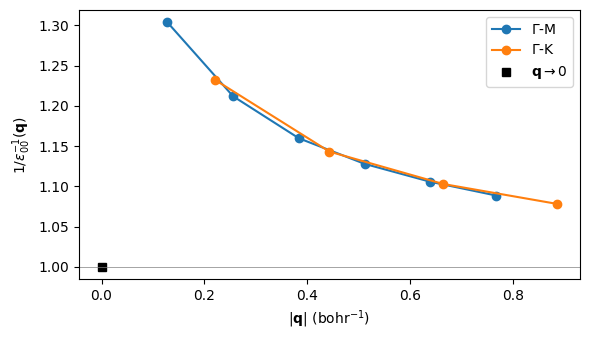

In [5]:
# chi0 recovered from X gives X back through the Dyson equation X = (1 - chi0)^-1 chi0
I = np.eye(scr.ng)
c0 = scr.chi0(5)
print('Dyson round trip at iq = 5, max |dX|: %.1e' % np.abs(np.linalg.solve(I - c0, c0) - scr.get_X(5)).max())

qn = np.linalg.norm(scr.q, axis=1)
qn[0] = 0
head = np.array([scr.eps_inv(iq)[0, 0, 0].real for iq in range(1, scr.nq + 1)])
qc = scr.q_crystal
lines = {r'$\Gamma$-M': np.where(np.isclose(qc[:, 0], 0))[0],
         r'$\Gamma$-K': np.where(np.isclose(qc[:, 0], qc[:, 1]))[0]}
fig, ax = plt.subplots(figsize=(6, 3.5))
for label, idx in lines.items():
    idx = idx[np.argsort(qn[idx])]
    print(label.replace('$', '').replace('\\', ''), '- q points:', (idx + 1).tolist())
    idx = idx[idx > 0]                       # q = 0 is plotted apart
    ax.plot(qn[idx], 1 / head[idx], 'o-', label=label)
ax.plot(0, 1 / head[0], 'ks', label=r'$\mathbf{q}\to 0$')
ax.axhline(1, color='gray', lw=0.5)
ax.set_xlabel(r'$|\mathbf{q}|$ (bohr$^{-1}$)')
ax.set_ylabel(r'$1/\epsilon^{-1}_{00}(\mathbf{q})$')
ax.legend()
plt.tight_layout()
plt.show()

## Symmetry transformations

`transform(X, iq, rotation, translation)` gives the X of the system moved by $\mathbf{r}\to R\mathbf{r}+\boldsymbol{\tau}$:

$$X'_{\mathbf{G}\mathbf{G}'}(\mathbf{q}) = e^{-i(\mathbf{G}-\mathbf{G}')\cdot\boldsymbol{\tau}}\,
X_{R^{-1}\mathbf{G},R^{-1}\mathbf{G}'}(R^{-1}\mathbf{q}) .$$

Only the operations with $R^{-1}\mathbf{q} = \pm\mathbf{q}$ are implemented (for $-\mathbf{q}$ the time reversal relation
$X_{\mathbf{G}\mathbf{G}'}(-\mathbf{q}) = X_{-\mathbf{G}',-\mathbf{G}}(\mathbf{q})$ is used; at $\mathbf{q} = 0$ the
direction of $\mathbf{q}_0$). The class checks that the G set is closed under R and that R leaves the (cut) Coulomb
interaction invariant, from the cutoff geometry written in the database: without cutoff any lattice operation is
allowed, with a slab cutoff (as here) R must map the normal axis onto $\pm$itself; for the other geometries the check is
not implemented and must be disabled explicitly (`check_cutoff=False`). The rotation is a cartesian orthogonal matrix,
the translation is in bohr.

A symmetry operation of the crystal must give X back. The attribute `syms` contains the cartesian matrices of the
`SAVE`, that Yambo applies to the k points. When the time reversal symmetry is used (`time_reversal` True, as for hBN,
which has no inversion), Yambo stores the spatial operations S in the first half of the list and the operations $-S$,
i.e. S combined with the time reversal, in the second half: only the first half are rotations of the crystal. We apply
them to every q point, when they map q onto $\pm$q.

In [6]:
print('operations in the SAVE:', len(scr.syms), '- time reversal:', scr.time_reversal)
spatial = scr.syms[:len(scr.syms) // 2] if scr.time_reversal else scr.syms
ndirect = nreversal = 0
dev = 0
for iq in range(1, scr.nq + 1):
    X = scr.get_X(iq)
    qv = scr.q0 if iq == 1 else scr.q[iq - 1]
    for R in spatial:
        try:
            Xt = scr.transform(X, iq, rotation=R)
        except NotImplementedError:          # R^-1 q is not +-q
            continue
        if np.allclose(R.T @ qv, qv, atol=1e-6):
            ndirect += 1
        else:
            nreversal += 1
        dev = max(dev, np.abs(Xt - X).max() / np.abs(X).max())
print('%d operations with R^-1 q = q, %d with R^-1 q = -q: max |X\' - X| / max |X| = %.1e' % (ndirect, nreversal, dev))

operations in the SAVE: 12 - time reversal: True
25 operations with R^-1 q = q, 4 with R^-1 q = -q: max |X' - X| / max |X| = 4.4e-06


With the slab cutoff the mirror reflection through the plane of the layer, $z \to 2z_0 - z$
($R = \mathrm{diag}(1, 1, -1)$, $\boldsymbol{\tau} = (0, 0, 2z_0)$), is a symmetry of the layer and gives X back at
every q point (also at q = 0, where the direction of $\mathbf{q}_0$ is in the plane), and so does a translation by a
lattice vector. The same reflection through $z = 0$ is not a symmetry, and neither are the rotation C2z about a B atom,
which maps B onto B but the N atoms onto empty sites, and the translation from the B to the N atom. A rotation that
exchanges x and z is refused, since it does not leave the slab-cut Coulomb interaction invariant.

In [7]:
B = atoms[0][1]
N = atoms[1][1]
mirror = np.diag([1., 1., -1.])
C2z = np.diag([-1., -1., 1.])
tests = {'mirror through the layer': dict(rotation=mirror, translation=[0, 0, 2 * z0]),
         'lattice translation': dict(translation=scr.lattice[0]),
         'mirror through z = 0': dict(rotation=mirror),
         'C2z about B': dict(rotation=C2z, translation=2 * B * [1, 1, 0]),
         'translation from B to N': dict(translation=N - B)}
dev = {key: [] for key in tests}
for iq in range(1, scr.nq + 1):
    X = scr.get_X(iq)
    for key, op in tests.items():
        try:
            Xt = scr.transform(X, iq, **op)
        except NotImplementedError:                              # R^-1 q is not +-q
            continue
        dev[key].append(np.linalg.norm(Xt - X) / np.linalg.norm(X))
for key, d in dev.items():
    print('%-25s ||X\' - X|| / ||X||: %.1e - %.1e (%d q points)' % (key, min(d), max(d), len(d)))
try:
    scr.transform(None, 2, rotation=[[0, 0, 1], [0, 1, 0], [1, 0, 0]])
except ValueError as e:
    print('ValueError:', e)

mirror through the layer  ||X' - X|| / ||X||: 3.5e-05 - 1.2e-04 (19 q points)
lattice translation       ||X' - X|| / ||X||: 1.1e-16 - 1.2e-16 (19 q points)
mirror through z = 0      ||X' - X|| / ||X||: 1.3e+00 - 1.4e+00 (19 q points)
C2z about B               ||X' - X|| / ||X||: 6.8e-01 - 7.1e-01 (19 q points)
translation from B to N   ||X' - X|| / ||X||: 6.2e-01 - 6.4e-01 (19 q points)
ValueError: The rotation does not map the z axis onto +-itself: it does not leave the Coulomb interaction with the cutoff "slab z" invariant


## Writing a new database

`write(dst, X)` writes a new database in the folder `dst`, with the database of the object as template: it copies the
header and all the fragments (only the `ndb.<kind>*` files) and replaces the matrices of the given q points (X is a
dictionary iq $\to$ matrix, or a function of iq). The X of the other q points is the one of the template. A fragment
that already exists in `dst` is rewritten only if its X differs by more than a tolerance, and every matrix written is
read back and checked. The header (bands, number of G vectors, cutoff, frequencies) stays the one of the template, so
Yambo assumes the parameters of the template.

Some precautions: `dst` cannot be the folder of the template, a folder with a database with a different header is
refused unless `overwrite=True`, and the `ndb.RIM_W` database is never copied (Yambo builds it from X and reuses a file
with a matching header without checking X: a database with a modified X must never carry an old `ndb.RIM_W`, a folder
that contains one is refused unless `overwrite=True`, which removes it).

As an example we write, at all the q points, the X of the layer translated in its plane from the B to the N atom (B
then sits on the site of N and N in the center of the hexagon).

In [8]:
out = 'YamboScreeningParser_tutorial'
if os.path.isdir(out):
    shutil.rmtree(out)
dst = os.path.join(out, 'em1s_translated')
moved = lambda iq: scr.transform(scr.get_X(iq), iq, translation=N - B)
summary = scr.write(dst, moved)

Database written in YamboScreeningParser_tutorial/em1s_translated: X written at 19 q points, 0 fragments copied from the template, 0 unchanged


In [9]:
new = YamboScreeningParser(dst, save, verbose=False)
err = max(np.abs(new.get_X(iq) - moved(iq)).max() for iq in range(1, scr.nq + 1))
print('database read back, max |X_read - X| = %.1e' % err)
print('files of the new folder:', len(os.listdir(dst)), '- ndb.RIM_W present:', os.path.isfile(os.path.join(dst, 'ndb.RIM_W')))
# a second call does not rewrite the fragments that are already up to date
summary = scr.write(dst, moved)

database read back, max |X_read - X| = 5.7e-10
files of the new folder: 20 - ndb.RIM_W present: False
Database written in YamboScreeningParser_tutorial/em1s_translated: X written at 0 q points, 0 fragments copied from the template, 19 unchanged


## Tools for 2D systems

For a 2D system (first two lattice vectors in the xy plane, third one along z, as in the `WfcParser` class; the methods
raise a ValueError otherwise) the method `inplane_blocks()` groups the G vectors by their in-plane part
$\mathbf{G}_\parallel$ (Miller indices $(m_1, m_2)$), `inplane_Q(iq, G_par)` gives
$\mathbf{Q} = \mathbf{q} + \mathbf{G}_\parallel$ and `planar(M, iq, G_par, z, z2)` gives the mixed representation of a
matrix M on the block $\mathbf{G}_\parallel = \mathbf{G}'_\parallel$:

$$M(\mathbf{Q}; z, z') = \frac{1}{c}\sum_{G_z, G_z'} e^{iG_z z} M_{\mathbf{G}\mathbf{G}'} e^{-iG_z' z'} .$$

In [10]:
blocks = scr.inplane_blocks()
print('%d in-plane vectors G_par; %d values of G_z for G_par = 0' % (len(blocks), len(blocks[(0, 0)])))
print('Q of the block G_par = (1, 0) at iq = 2 (bohr^-1):', np.round(scr.inplane_Q(2, (1, 0)), 4))

13 in-plane vectors G_par; 37 values of G_z for G_par = 0
Q of the block G_par = (1, 0) at iq = 2 (bohr^-1): [1.3278 0.8944 0.    ]


The matrix X in the mixed representation, with $z'$ on the plane of the layer, shows that the response is localized
around the layer (here at the first q point after $\Gamma$ and for $\mathbf{G}_\parallel = 0$): the sum over
$G_z$ is limited to the 37 values of the database, so the profile is smoothed on a length $\sim 2\pi/G_z^{\max}$.

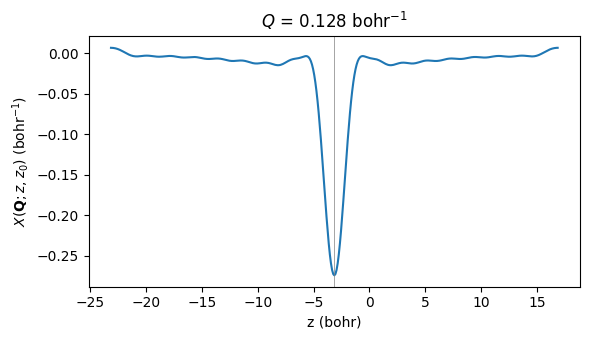

In [11]:
iq = 2
c_len = scr.lattice[2, 2]
z = np.linspace(z0 - c_len / 2, z0 + c_len / 2, 401)
Xz = scr.planar(scr.get_X(iq)[0], iq, (0, 0), z, z0)[:, 0]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(z, Xz.real)
ax.axvline(z0, color='gray', lw=0.5)
ax.set_xlabel('z (bohr)')
ax.set_ylabel(r'$X(\mathbf{Q}; z, z_0)$ (bohr$^{-1}$)')
ax.set_title(r'$Q$ = %.3f bohr$^{-1}$' % np.linalg.norm(scr.inplane_Q(iq)[:2]))
plt.tight_layout()
plt.show()